# Vehicle Energy Dataset (VED)

This notebook lists the vehicles of the two static workbooks, loads one week of one electric vehicle, and plots its battery SOC. It makes no diagnosis.

## 1. Released units

This step lists what `systems('ved')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('ved')
display(released)

,unit,group,VehId,Vehicle Type,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight,battery_signals,rated_kwh_stated
0,2,ICE&HEV,2,ICE,Car,4-FI 2.0L T/C,NO DATA,NO DATA,3500,False,NaN
1,5,ICE&HEV,5,HEV,Car,4-GAS/ELECTRIC 2.0L,NO DATA,NO DATA,3500,False,NaN
2,7,ICE&HEV,7,ICE,SUV,6-FI 3.6L,AUTOMATIC,NO DATA,4500,False,NaN
3,8,ICE&HEV,8,ICE,Car,4-FI 1.5L,5-SP MANUAL,NO DATA,2500,False,NaN
4,12,ICE&HEV,12,ICE,Car,4-FI 1.8L,NO DATA,NO DATA,2500,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...
379,554,PHEV&EV,554,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000,True,NaN
380,560,PHEV&EV,560,PHEV,Car,4-GAS/ELECTRIC 1.8L,CVT,FWD,3000,True,NaN
381,561,PHEV&EV,561,PHEV,Car,4-GAS/ELECTRIC 2.0L,CVT,FWD,4000,True,NaN
382,567,PHEV&EV,567,PHEV,Car,4-GAS/ELECTRIC 1.4L,NO DATA,FWD,4000,True,NaN


Each row is one vehicle. battery_signals is True for the 27 PHEV and EV. Vehicle 439, listed as an HEV, also carries battery signals.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('ved', unit=10, week='171101')
print(frame.shape)
display(frame.head())

(2656, 23)


,week,DayNum,VehId,Trip,Timestamp(ms),Latitude[deg],Longitude[deg],Vehicle Speed[km/h],MAF[g/sec],Engine RPM[RPM],...,Air Conditioning Power[kW],Air Conditioning Power[Watts],Heater Power[Watts],HV Battery Current[A],HV Battery SOC[%],HV Battery Voltage[V],Short Term Fuel Trim Bank 1[%],Short Term Fuel Trim Bank 2[%],Long Term Fuel Trim Bank 1[%],Long Term Fuel Trim Bank 2[%]
0,171101,1.719774,10,1558,0,42.277066,-83.763404,53.590000,NaN,NaN,...,NaN,0.0,2250.0,-21.5,96.341469,386.0,NaN,NaN,NaN,NaN
1,171101,1.719774,10,1558,200,42.277066,-83.763404,51.980000,NaN,NaN,...,NaN,0.0,2250.0,-21.5,96.341469,386.0,NaN,NaN,NaN,NaN
2,171101,1.719774,10,1558,1200,42.277066,-83.763404,50.369999,NaN,NaN,...,NaN,0.0,2250.0,-21.5,96.341469,386.0,NaN,NaN,NaN,NaN
3,171101,1.719774,10,1558,1500,42.277066,-83.763404,50.369999,NaN,NaN,...,NaN,0.0,2250.0,23.5,96.341469,390.5,NaN,NaN,NaN,NaN
4,171101,1.719774,10,1558,2300,42.277066,-83.763404,49.799999,NaN,NaN,...,NaN,0.0,2250.0,23.5,96.341469,390.5,NaN,NaN,NaN,NaN


The week from 1 November 2017 for vehicle 10, a 2013 Nissan Leaf. Signals update at different rates, so many cells are empty between updates.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['HV Battery Current[A]', 'HV Battery SOC[%]', 'HV Battery Voltage[V]']].describe().T)

,count,mean,std,min,25%,50%,75%,max
HV Battery Current[A],2656.0,-14.185429,27.439877,-129.000000,-28.000000,-9.000000,0.000000,50.5
HV Battery SOC[%],2656.0,75.647271,18.418082,46.585369,64.634148,69.634148,95.853661,100.0
HV Battery Voltage[V],2656.0,380.614081,7.092035,358.000000,375.500000,380.000000,387.000000,394.0


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

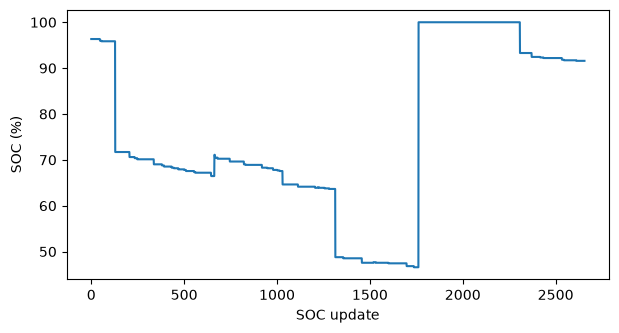

In [4]:
soc = frame['HV Battery SOC[%]'].dropna().reset_index(drop=True)
ax = soc.plot(figsize=(7, 3.5))
ax.set_xlabel('SOC update')
ax.set_ylabel('SOC (%)')
plt.show()

Over the eight trips of that week vehicle 10's SOC ranges from 47 to 100 percent. Values are raw, as released.